# Procesarea Semnalelor – Laboratorul 3
## Transformata Fourier – Partea I

Transformata Fourier a unui semnal discret $x[n]$:

$$X(\omega) = \sum_{n=0}^{N-1} x[n]\, e^{-2\pi j n \omega / N}$$

Transformata este calculată „de mână”, **fără** `numpy.fft` / `scipy.fft`: întâi cu bucle explicite, apoi cu matricea Fourier (produs matrice–vector).
Toate graficele se salvează în format **PDF** în folderul `grafice/`.

In [1]:
import math
import os

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display

os.makedirs("grafice", exist_ok=True)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["animation.embed_limit"] = 50  # MB, pentru animatiile afisate in notebook

## Exercițiul 1 – Matricea Fourier pentru N = 8

Elementele matricei Fourier sunt

$$F_{k,n} = e^{-2\pi j k n / N}, \qquad k, n = 0, \dots, N-1$$

Fiecare linie $k$ este o sinusoidă complexă de frecvență $k$. Desenăm partea reală și partea imaginară a fiecărei linii pe câte un subplot.

In [2]:
def matrice_fourier(N):
    # cu bucle explicite, folosind math (ca in ghidul Python)
    F = np.zeros((N, N), dtype=complex)
    for k in range(N):
        for n in range(N):
            F[k, n] = math.e ** (-2j * math.pi * k * n / N)
    return F

N = 8
F = matrice_fourier(N)
print(np.round(F, 3))

[[ 1.   +0.j     1.   +0.j     1.   +0.j     1.   +0.j     1.   +0.j
   1.   +0.j     1.   +0.j     1.   +0.j   ]
 [ 1.   +0.j     0.707-0.707j  0.   -1.j    -0.707-0.707j -1.   -0.j
  -0.707+0.707j -0.   +1.j     0.707+0.707j]
 [ 1.   +0.j     0.   -1.j    -1.   -0.j    -0.   +1.j     1.   +0.j
   0.   -1.j    -1.   -0.j    -0.   +1.j   ]
 [ 1.   +0.j    -0.707-0.707j -0.   +1.j     0.707-0.707j -1.   -0.j
   0.707+0.707j  0.   -1.j    -0.707+0.707j]
 [ 1.   +0.j    -1.   -0.j     1.   +0.j    -1.   -0.j     1.   +0.j
  -1.   -0.j     1.   +0.j    -1.   -0.j   ]
 [ 1.   +0.j    -0.707+0.707j  0.   -1.j     0.707+0.707j -1.   -0.j
   0.707-0.707j -0.   +1.j    -0.707-0.707j]
 [ 1.   +0.j    -0.   +1.j    -1.   -0.j     0.   -1.j     1.   +0.j
  -0.   +1.j    -1.   -0.j    -0.   -1.j   ]
 [ 1.   +0.j     0.707+0.707j -0.   +1.j    -0.707+0.707j -1.   -0.j
  -0.707-0.707j -0.   -1.j     0.707-0.707j]]


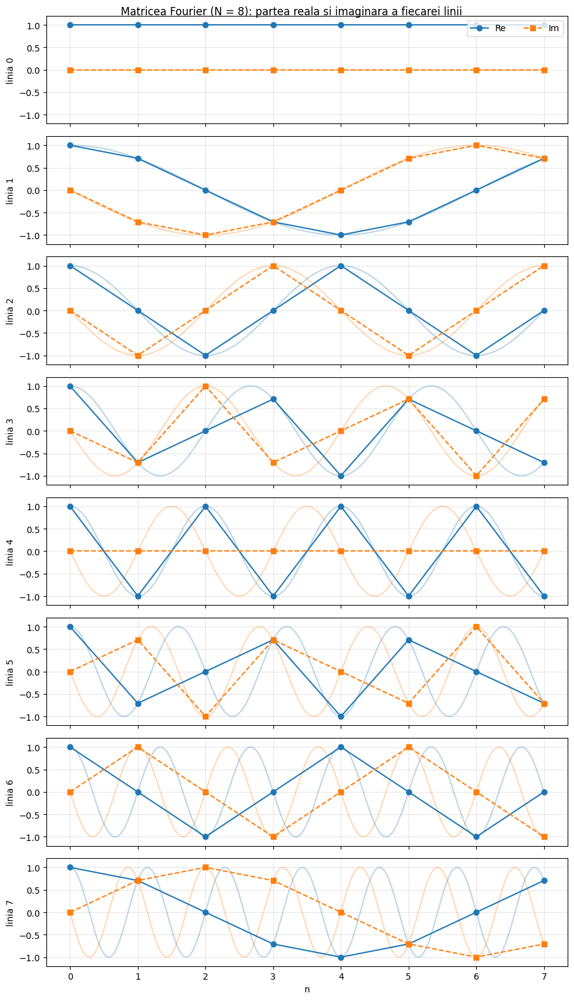

In [3]:
n = np.arange(N)
n_fin = np.linspace(0, N - 1, 400)  # curba continua, doar pentru vizualizare

fig, axs = plt.subplots(N, 1, figsize=(9, 2 * N), sharex=True)
for k in range(N):
    ax = axs[k]
    ax.plot(n_fin, np.cos(-2 * np.pi * k * n_fin / N), color="tab:blue", alpha=0.3)
    ax.plot(n_fin, np.sin(-2 * np.pi * k * n_fin / N), color="tab:orange", alpha=0.3)
    ax.plot(n, F[k].real, "o-", color="tab:blue", label="Re")
    ax.plot(n, F[k].imag, "s--", color="tab:orange", label="Im")
    ax.set_ylabel(f"linia {k}")
    ax.set_ylim(-1.2, 1.2)
    ax.grid(alpha=0.3)
axs[0].legend(loc="upper right", ncol=2)
axs[-1].set_xlabel("n")
fig.suptitle("Matricea Fourier (N = 8): partea reala si imaginara a fiecarei linii")
fig.tight_layout()
fig.savefig("grafice/ex1_matrice_fourier.pdf")
plt.show()

### Verificarea unitarității

$F$ este unitară (până la o constantă) dacă $F^H F = N \cdot I$, unde $F^H$ este transpusa conjugată.
Echivalent, matricea normalizată $\frac{1}{\sqrt{N}} F$ satisface exact $U^H U = I$.

In [4]:
FH_F = F.conj().T @ F
print("F^H F =")
print(np.round(FH_F.real, 6))

print("\nF^H F == N * I ?          ", np.allclose(FH_F, N * np.eye(N)))
print("|| F^H F - N*I ||_F       =", np.linalg.norm(FH_F - N * np.eye(N)))

U = F / np.sqrt(N)
print("U = F/sqrt(N) unitara ?   ", np.allclose(U.conj().T @ U, np.eye(N)))

F^H F =
[[ 8. -0. -0. -0.  0. -0. -0.  0.]
 [-0.  8.  0.  0. -0. -0.  0.  0.]
 [-0.  0.  8. -0. -0.  0.  0.  0.]
 [-0.  0. -0.  8. -0. -0.  0.  0.]
 [ 0. -0. -0. -0.  8. -0.  0. -0.]
 [-0. -0.  0. -0. -0.  8.  0.  0.]
 [-0.  0.  0.  0.  0.  0.  8. -0.]
 [ 0.  0.  0.  0. -0.  0. -0.  8.]]

F^H F == N * I ?           True
|| F^H F - N*I ||_F       = 2.129086192035749e-14
U = F/sqrt(N) unitara ?    True


### Transformata Fourier: bucle explicite vs. produs matrice–vector

Implementăm relația (1) în ambele moduri și verificăm că dau același rezultat (comparăm cu `np.fft.fft` **doar** ca verificare).

In [5]:
def dft_bucle(x):
    N = len(x)
    X = np.zeros(N, dtype=complex)
    for k in range(N):
        s = 0
        for n in range(N):
            s += x[n] * math.e ** (-2j * math.pi * n * k / N)
        X[k] = s
    return X

def dft_matrice(x):
    return matrice_fourier(len(x)) @ x

x_test = np.random.randn(N)
X1 = dft_bucle(x_test)
X2 = dft_matrice(x_test)
print("bucle == matrice:   ", np.allclose(X1, X2))
print("matrice == np.fft:  ", np.allclose(X2, np.fft.fft(x_test)), "(doar verificare)")

bucle == matrice:    True
matrice == np.fft:   True (doar verificare)


## Exercițiul 2 – Înfășurarea semnalului pe cercul unitate

Alegem un semnal sinusoidal cu frecvența **f = 7 Hz** (diferită de cea din îndrumar), eșantionat cu 1000 de eșantioane pe o secundă.

* **Figura 1**: semnalul în timp (stânga) și $y[n] = x[n]\,e^{-2\pi j n}$ în planul complex (dreapta), cu $n$ parcurgând intervalul $[0, 1)$.
* **Figura 2**: $z[\omega] = x[n]\,e^{-2\pi j \omega n}$ pentru patru frecvențe de înfășurare, dintre care una egală cu frecvența semnalului.

Culoarea fiecărui punct depinde de **distanța față de origine** $|y[n]|$, respectiv $|z[n]|$.

In [6]:
f = 7                        # frecventa semnalului (Hz)
N2 = 1000                    # numar de esantioane
t = np.arange(N2) / N2       # timp in [0, 1) secunde
x = np.sin(2 * np.pi * f * t)

y = x * np.exp(-2j * np.pi * t)             # infasurare cu omega = 1
omegas = [1, 3, f, 10]                      # frecvente de infasurare (una = f)
zs = {w: x * np.exp(-2j * np.pi * w * t) for w in omegas}

idx = 620                    # esantionul marcat cu rosu (ca in indrumar)
cmap = "viridis"

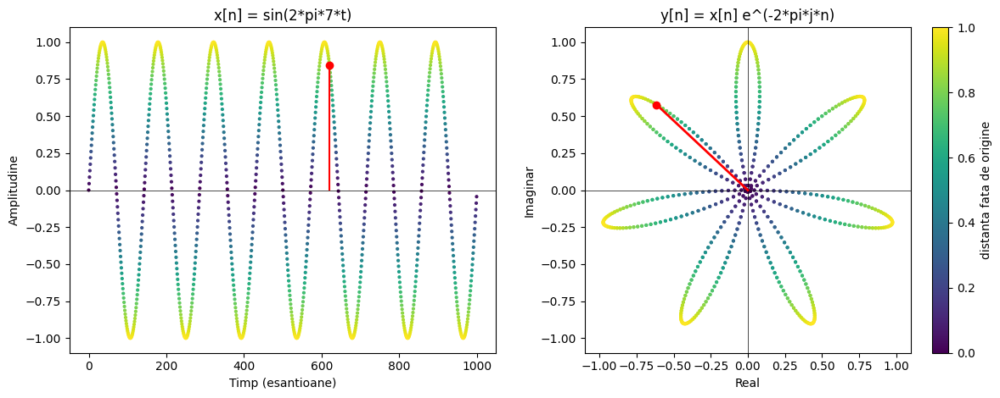

In [7]:
def cerc_plot(ax, z, titlu=None, cu_bara=False):
    sc = ax.scatter(z.real, z.imag, c=np.abs(z), cmap=cmap, s=4, vmin=0, vmax=1)
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
    ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
    ax.set_aspect("equal")
    ax.set_xlabel("Real"); ax.set_ylabel("Imaginar")
    if titlu: ax.set_title(titlu)
    if cu_bara: plt.colorbar(sc, ax=ax, label="distanta fata de origine")
    return sc

# ---------- Figura 1 (statica) ----------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

ax1.scatter(np.arange(N2), x, c=np.abs(x), cmap=cmap, s=4, vmin=0, vmax=1)
ax1.stem([idx], [x[idx]], linefmt="r-", markerfmt="ro", basefmt=" ")
ax1.axhline(0, color="k", lw=0.5)
ax1.set_xlabel("Timp (esantioane)"); ax1.set_ylabel("Amplitudine")
ax1.set_title(f"x[n] = sin(2*pi*{f}*t)")

cerc_plot(ax2, y, "y[n] = x[n] e^(-2*pi*j*n)", cu_bara=True)
ax2.plot([0, y[idx].real], [0, y[idx].imag], "r-", lw=2)
ax2.plot(y[idx].real, y[idx].imag, "ro")

fig.tight_layout()
fig.savefig("grafice/ex2_figura1.pdf")
plt.show()

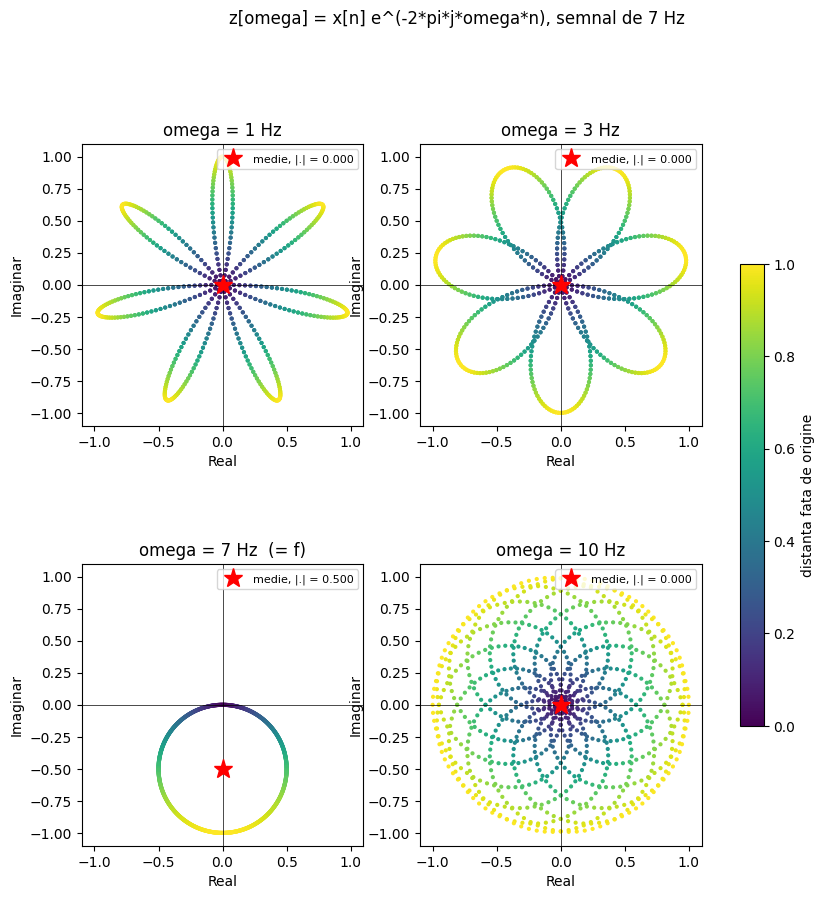

In [8]:
# ---------- Figura 2 (statica) ----------
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for ax, w in zip(axs.flat, omegas):
    z = zs[w]
    titlu = f"omega = {w} Hz" + ("  (= f)" if w == f else "")
    sc = cerc_plot(ax, z, titlu)
    # centrul de greutate al infasurarii ~ X(omega)/N
    c = z.mean()
    ax.plot(c.real, c.imag, "r*", ms=14, label=f"medie, |.| = {abs(c):.3f}")
    ax.legend(loc="upper right", fontsize=8)
fig.colorbar(sc, ax=axs, shrink=0.6, label="distanta fata de origine")
fig.suptitle(f"z[omega] = x[n] e^(-2*pi*j*omega*n), semnal de {f} Hz")
fig.savefig("grafice/ex2_figura2.pdf")
plt.show()

**Observație:** pentru $\omega \neq f$ înfășurarea este simetrică în jurul originii, deci media punctelor (steaua roșie) este ≈ 0.
Pentru $\omega = f$ toate „petalele” cad de aceeași parte, iar media se depărtează de origine: exact asta măsoară $|X(\omega)|$.

### Versiunea animată

Desenăm punctele în timp real, în ordinea în care sunt parcurse, iar **punctul curent** este marcat cu un indicator separat (punct roșu și segment până la origine). Așa se vede ordinea punctelor și sensul de parcurgere pe cerc (sens orar, din cauza semnului minus din exponent).

`PAS` controlează viteza: câte eșantioane noi se desenează pe fiecare cadru.

In [9]:
PAS = 10          # esantioane noi pe cadru (viteza)
INTERVAL = 30     # ms intre cadre
cadre = range(PAS, N2 + 1, PAS)

# ---------- Figura 1 animata ----------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
ax1.set_xlim(0, N2); ax1.set_ylim(-1.1, 1.1)
ax1.axhline(0, color="k", lw=0.5)
ax1.set_xlabel("Timp (esantioane)"); ax1.set_ylabel("Amplitudine")
ax1.set_title(f"x[n] = sin(2*pi*{f}*t)")
sc1 = ax1.scatter([], [], c=[], cmap=cmap, s=4, vmin=0, vmax=1)
pt1, = ax1.plot([], [], "ro", ms=8)
lin1, = ax1.plot([], [], "r-", lw=2)

sc2 = cerc_plot(ax2, y[:1], "y[n] = x[n] e^(-2*pi*j*n)")
pt2, = ax2.plot([], [], "ro", ms=8)
lin2, = ax2.plot([], [], "r-", lw=2)
fig.tight_layout()

def update1(i):
    k = i - 1
    sc1.set_offsets(np.c_[np.arange(i), x[:i]]); sc1.set_array(np.abs(x[:i]))
    pt1.set_data([k], [x[k]]); lin1.set_data([k, k], [0, x[k]])
    sc2.set_offsets(np.c_[y[:i].real, y[:i].imag]); sc2.set_array(np.abs(y[:i]))
    pt2.set_data([y[k].real], [y[k].imag]); lin2.set_data([0, y[k].real], [0, y[k].imag])
    return sc1, pt1, lin1, sc2, pt2, lin2

anim1 = animation.FuncAnimation(fig, update1, frames=cadre, interval=INTERVAL, blit=True)
plt.close(fig)
display(HTML(anim1.to_jshtml()))

In [10]:
# ---------- Figura 2 animata ----------
fig, axs = plt.subplots(2, 2, figsize=(9, 9))
elem = []
for ax, w in zip(axs.flat, omegas):
    sc = cerc_plot(ax, zs[w][:1], f"omega = {w} Hz" + ("  (= f)" if w == f else ""))
    pt, = ax.plot([], [], "ro", ms=7)
    ln, = ax.plot([], [], "r-", lw=1.5)
    elem.append((w, sc, pt, ln))
fig.tight_layout()

def update2(i):
    k = i - 1
    art = []
    for w, sc, pt, ln in elem:
        z = zs[w]
        sc.set_offsets(np.c_[z[:i].real, z[:i].imag]); sc.set_array(np.abs(z[:i]))
        pt.set_data([z[k].real], [z[k].imag]); ln.set_data([0, z[k].real], [0, z[k].imag])
        art += [sc, pt, ln]
    return art

anim2 = animation.FuncAnimation(fig, update2, frames=cadre, interval=INTERVAL, blit=True)
plt.close(fig)
display(HTML(anim2.to_jshtml()))

*Opțional:* animațiile se pot salva și ca GIF (necesită `pillow`):

```python
anim1.save("grafice/ex2_figura1_animata.gif", writer="pillow", fps=30)
anim2.save("grafice/ex2_figura2_animata.gif", writer="pillow", fps=30)
```

## Exercițiul 3 – Modulul transformatei Fourier pentru un semnal cu 3 componente

$$x[n] = 1.5\cos(2\pi f_1 n t_s) + \cos(2\pi f_2 n t_s) + 0.7\cos(2\pi f_3 n t_s)$$

cu $f_1 = 8$ Hz, $f_2 = 30$ Hz, $f_3 = 65$ Hz, $f_s = 1000$ Hz și durată 1 s ($N = 1000$).

Frecvențele de înfășurare $\omega$ sunt alese în Hz: înlocuind $n$ cu $n t_s = n / f_s$, relația (1) devine

$$X(\omega) = \sum_{n=0}^{N-1} x[n]\, e^{-2\pi j \omega n / f_s}$$

Cum semnalul durează 1 s, rezoluția în frecvență este $f_s / N = 1$ Hz, așa că alegem $\omega \in \{1, 2, \dots, 100\}$ Hz, plajă care acoperă toate cele trei componente (cea mai mare este 65 Hz).

In [11]:
fs = 1000
N3 = 1000
ts = 1 / fs
n3 = np.arange(N3)
t3 = n3 * ts

f1, f2, f3 = 8, 30, 65
x3 = 1.5 * np.cos(2 * np.pi * f1 * t3) + np.cos(2 * np.pi * f2 * t3) + 0.7 * np.cos(2 * np.pi * f3 * t3)

omega = np.arange(1, 101)   # frecvente de infasurare (Hz)

In [12]:
# ---------- varianta 1: bucle explicite ----------
def fourier_bucle(x, omega, fs):
    X = np.zeros(len(omega), dtype=complex)
    for i, w in enumerate(omega):
        s = 0
        for n in range(len(x)):
            s += x[n] * math.e ** (-2j * math.pi * w * n / fs)
        X[i] = s
    return X

# ---------- varianta 2: matrice Fourier (linii = frecvente omega) si produs matrice-vector ----------
def fourier_matrice(x, omega, fs):
    n = np.arange(len(x))
    M = np.exp(-2j * np.pi * np.outer(omega, n) / fs)
    return M @ x

X_bucle = fourier_bucle(x3, omega, fs)
X_mat = fourier_matrice(x3, omega, fs)
print("bucle == matrice:", np.allclose(X_bucle, X_mat))

bucle == matrice: True


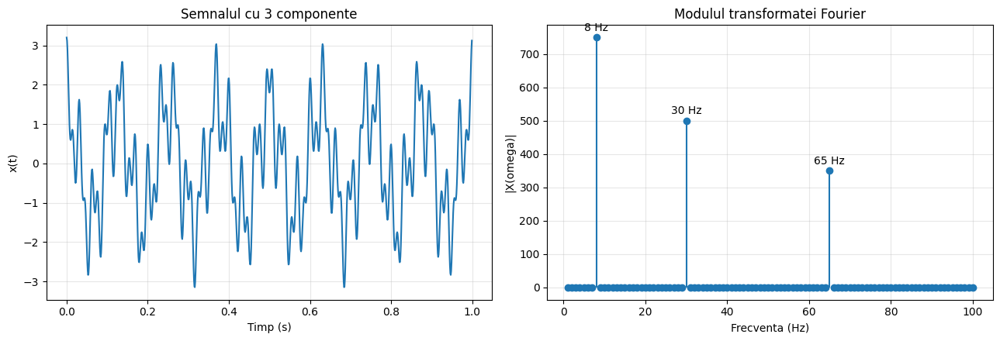

In [13]:
modul = np.abs(X_mat)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(t3, x3)
ax1.set_xlabel("Timp (s)"); ax1.set_ylabel("x(t)")
ax1.set_title("Semnalul cu 3 componente")
ax1.grid(alpha=0.3)

ax2.stem(omega, modul, basefmt=" ")
ax2.set_xlabel("Frecventa (Hz)"); ax2.set_ylabel("|X(omega)|")
ax2.set_title("Modulul transformatei Fourier")
ax2.grid(alpha=0.3)
for fk in (f1, f2, f3):
    ax2.annotate(f"{fk} Hz", (fk, modul[fk - 1]), textcoords="offset points", xytext=(0, 6), ha="center")

fig.tight_layout()
fig.savefig("grafice/ex3_transformata_fourier.pdf")
plt.show()

In [14]:
# frecventele detectate: unde modulul e semnificativ diferit de 0
detectate = omega[modul > 0.1 * modul.max()]
print("Frecvente detectate:", detectate, "Hz")

# pentru o componenta A*cos, |X(f)| = A * N / 2  ->  putem recupera si amplitudinile
for fk in detectate:
    print(f"  {fk:3d} Hz -> amplitudine estimata = {2 * modul[fk - 1] / N3:.2f}")

Frecvente detectate: [ 8 30 65] Hz
    8 Hz -> amplitudine estimata = 1.50
   30 Hz -> amplitudine estimata = 1.00
   65 Hz -> amplitudine estimata = 0.70


**Concluzie:** modulul transformatei este diferit de 0 doar pentru $\omega = 8, 30, 65$ Hz, adică exact frecvențele componentelor semnalului. Înălțimea fiecărui vârf este $A \cdot N / 2$, deci din grafic putem recupera și amplitudinile (1.5, 1 și 0.7).